# ML Workflow in der Praxis: Gehälter von Baseballspielern

In diesem Notebook gehen wir den kompletten ML-Workflow aus der Vorlesung einmal in Code durch:

1. Daten laden und verstehen (EDA)
2. Datenbereinigung: Duplikate, fehlende Werte, Ausreißer
3. Train/Test-Split
4. Feature Engineering: irrelevante Attribute, neue Features, kategorische Features
5. Feature Scaling
6. Alles zusammen: sklearn `Pipeline` und Training

**Datensatz:** `hitters.csv`: Statistiken von 322 Baseballspielern (Saison 1986 und Karriere) sowie ihr Gehalt 1987 in Tausend Dollar.
**Ziel:** Vorhersage des Gehalts (`Salary`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Daten laden und verstehen

In [2]:
data_raw = pd.read_csv("data/hitters.csv")
print(data_raw.shape)
data_raw.head()

(322, 21)


,Player,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,...,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,-Andy Allanson,293,66,1,30,29,14,1,293,66,...,30,29,14,A,E,446,33,20,NaN,A
1,-Alan Ashby,315,81,7,24,38,39,14,3449,835,...,321,414,375,N,W,632,43,10,475.0,N
2,-Alvin Davis,479,130,18,66,72,76,3,1624,457,...,224,266,263,A,W,880,82,14,480.0,A
3,-Andre Dawson,496,141,20,65,78,37,11,5628,1575,...,828,838,354,N,E,200,11,3,500.0,N
4,-Andres Galarraga,321,87,10,39,42,30,2,396,101,...,48,46,33,N,E,805,40,4,91.5,N


In [3]:
# Datentypen und fehlende Werte auf einen Blick
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 21 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Player     322 non-null    str    
 1   AtBat      322 non-null    int64  
 2   Hits       322 non-null    int64  
 3   HmRun      322 non-null    int64  
 4   Runs       322 non-null    int64  
 5   RBI        322 non-null    int64  
 6   Walks      322 non-null    int64  
 7   Years      322 non-null    int64  
 8   CAtBat     322 non-null    int64  
 9   CHits      322 non-null    int64  
 10  CHmRun     322 non-null    int64  
 11  CRuns      322 non-null    int64  
 12  CRBI       322 non-null    int64  
 13  CWalks     322 non-null    int64  
 14  League     322 non-null    str    
 15  Division   322 non-null    str    
 16  PutOuts    322 non-null    int64  
 17  Assists    322 non-null    int64  
 18  Errors     322 non-null    int64  
 19  Salary     263 non-null    float64
 20  NewLeague  322 non-nu

Beobachtungen:
- `League`, `Division`, `NewLeague` sind **kategorische** Attribute (Typ `object`/`str`).
- `Salary` hat nur 263 statt 322 Einträge, es fehlen also **Werte im Label**.

In [4]:
# Statistische Kennzahlen der numerischen Attribute
data_raw.describe().round(1)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
count,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,322.0,263.0
mean,380.9,101.0,10.8,50.9,48.0,38.7,7.4,2648.7,717.6,69.5,358.8,330.1,260.2,288.9,106.9,8.0,535.9
std,153.4,46.5,8.7,26.0,26.2,21.6,4.9,2324.2,654.5,86.3,334.1,333.2,267.1,280.7,136.9,6.4,451.1
min,16.0,1.0,0.0,0.0,0.0,0.0,1.0,19.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,67.5
25%,255.2,64.0,4.0,30.2,28.0,22.0,4.0,816.8,209.0,14.0,100.2,88.8,67.2,109.2,7.0,3.0,190.0
50%,379.5,96.0,8.0,48.0,44.0,35.0,6.0,1928.0,508.0,37.5,247.0,220.5,170.5,212.0,39.5,6.0,425.0
75%,512.0,137.0,16.0,69.0,64.8,53.0,11.0,3924.2,1059.2,90.0,526.2,426.2,339.2,325.0,166.0,11.0,750.0
max,687.0,238.0,40.0,130.0,121.0,105.0,24.0,14053.0,4256.0,548.0,2165.0,1659.0,1566.0,1378.0,492.0,32.0,2460.0


### Verteilungen: Histogramm und Boxplot

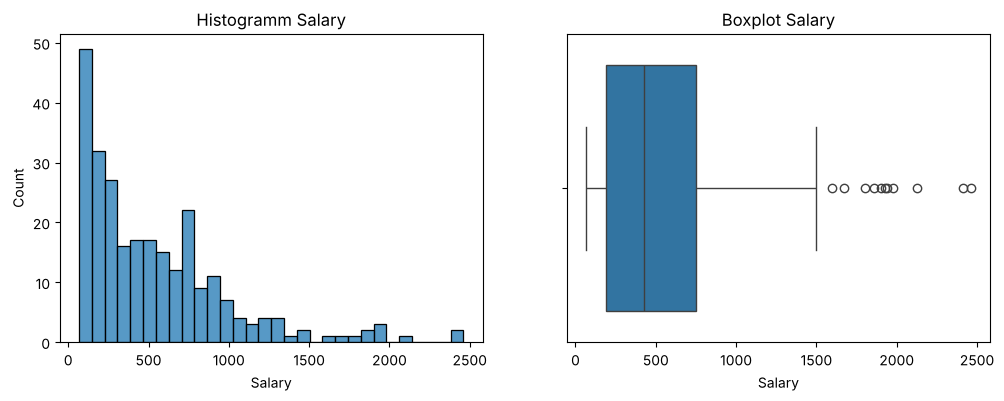

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data_raw["Salary"], bins=30, ax=axes[0])
axes[0].set_title("Histogramm Salary")
sns.boxplot(x=data_raw["Salary"], ax=axes[1])
axes[1].set_title("Boxplot Salary")
plt.show()

Das Gehalt ist stark **rechtsschief**: Die meisten Spieler verdienen wenig, einige wenige Stars sehr viel.
Die Punkte rechts im Boxplot liegen außerhalb von Q3 + 1.5 · IQR.

### Zusammenhang mit dem Label

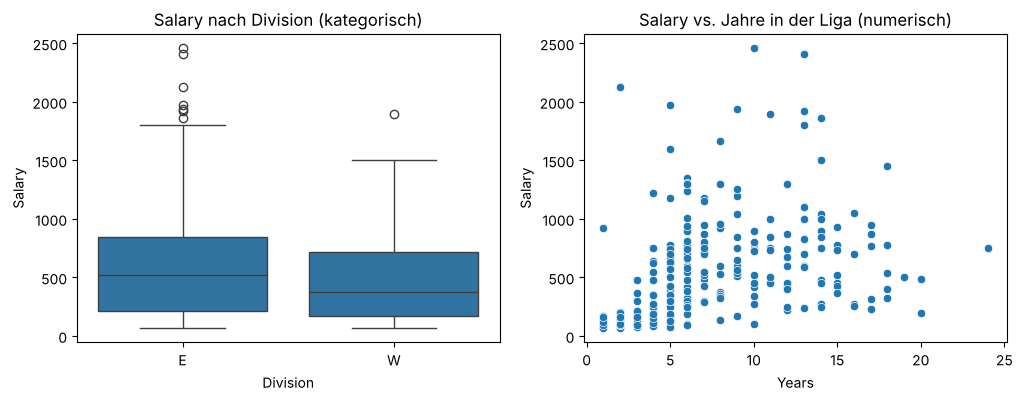

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data_raw, x="Division", y="Salary", ax=axes[0])
axes[0].set_title("Salary nach Division (kategorisch)")
sns.scatterplot(data=data_raw, x="Years", y="Salary", ax=axes[1])
axes[1].set_title("Salary vs. Jahre in der Liga (numerisch)")
plt.show()

Gehalt steigt mit der Erfahrung, allerdings **nicht linear**: Nach ca. 10 Jahren flacht es wieder ab.

Auffällig: ein Spieler mit nur 2 Jahren Erfahrung und über 2.000 Tsd. $ Gehalt. Den schauen wir uns gleich bei den Ausreißern an.

### Korrelationen

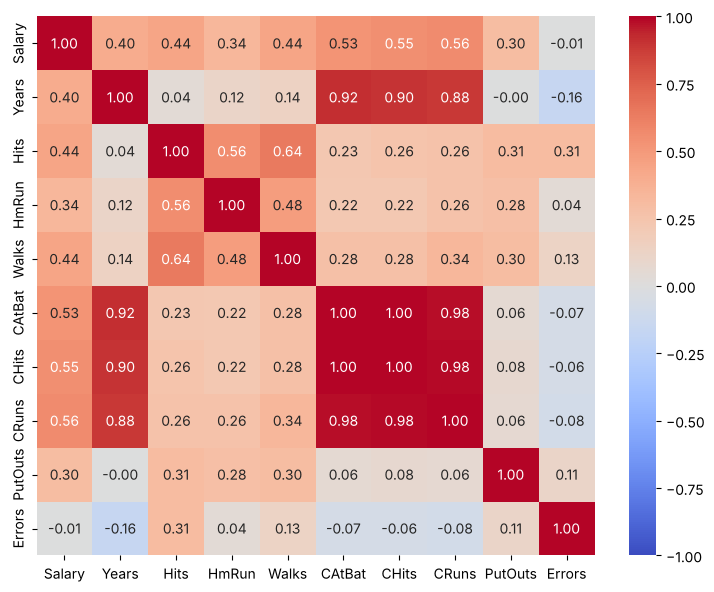

In [7]:
cols = ["Salary", "Years", "Hits", "HmRun", "Walks", "CAtBat", "CHits", "CRuns", "PutOuts", "Errors"]
plt.figure(figsize=(9, 7))
sns.heatmap(data_raw[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

- Die **Karriere-Statistiken** (`CAtBat`, `CHits`, `CRuns`) korrelieren am stärksten mit dem Gehalt.
- Sie korrelieren aber auch fast perfekt **untereinander** (≈ 0.99): Hinweis auf **Redundanz**.
- `Errors` und `PutOuts` haben kaum linearen Zusammenhang mit dem Gehalt.

## 2. Datenbereinigung

### Inkonsistente Werte

In [8]:
# Spielernamen beginnen mit einem "-": typisches Artefakt aus der Datenextraktion
data_raw["Player"].head(3).tolist()

['-Andy Allanson', '-Alan Ashby', '-Alvin Davis']

In [9]:
data = data_raw.copy()
data["Player"] = data["Player"].str.lstrip("-").str.strip()
data["Player"].head(3).tolist()

['Andy Allanson', 'Alan Ashby', 'Alvin Davis']

### Duplikate

In [10]:
print("Exakte Duplikate:", data.duplicated().sum())
print("Doppelte Spielernamen:", data["Player"].duplicated().sum())

Exakte Duplikate: 0
Doppelte Spielernamen: 0


### Fehlende Werte
Fehlende Werte gibt es nur im **Label** `Salary`. Ohne Label können wir nicht trainieren,
und ein imputiertes Label wäre eine „erfundene“ Wahrheit. Deshalb **entfernen** wir diese Zeilen.

In [11]:
print(data.isna().sum()[data.isna().sum() > 0])
data = data.dropna(subset=["Salary"])
print("Verbleibende Zeilen:", len(data))

Salary    59
dtype: int64
Verbleibende Zeilen: 263


### Ausreißer
Wir bestimmen Ausreißer mit der IQR-Regel aus dem Boxplot:

In [12]:
q1, q3 = data["Salary"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, obere Grenze = {upper:.0f}")
data.loc[data["Salary"] > upper, ["Player", "Years", "CHits", "Salary"]].sort_values("Salary", ascending=False).head()

Q1 = 190, Q3 = 750, obere Grenze = 1590


,Player,Years,CHits,Salary
100,Eddie Murray,10,1679,2460.000
163,Jim Rice,13,2163,2412.500
217,Mike Schmidt,2,9,2127.333
82,Don Mattingly,5,737,1975.000
229,Ozzie Smith,9,1169,1940.000


**Eddie Murray** und **Jim Rice** sind echte Topverdiener mit langer Karriere: plausibel, also **behalten**.

**Mike Schmidt** dagegen hat 2 Jahre Erfahrung, 9 Hits in der gesamten Karriere und ist trotzdem der drittbeste Verdiener.
Das ist **inkonsistent** und wahrscheinlich ein Datenfehler (z. B. falsch zusammengeführte Datensätze).
Nur solche Ausreißer entfernen wir.

In [13]:
data = data[data["Player"] != "Mike Schmidt"]
print("Verbleibende Zeilen:", len(data))

Verbleibende Zeilen: 262


## 3. Train/Test-Split
Ab hier gilt: Alle Parameter (Mittelwerte, σ, Kategorien, ...) werden **nur auf den Trainingsdaten** bestimmt.
Darum splitten wir **vor** dem Imputieren, Encodieren und Skalieren.

In [14]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["Salary"])
y = data["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(209, 20) (53, 20)


## 4. Feature Engineering

### Irrelevante Attribute entfernen
- `Player`: der Name ist ein eindeutiger Identifier und trägt keine verallgemeinerbare Information.
- `NewLeague`: fast identisch zu `League` (siehe Kreuztabelle) und damit redundant.

In [15]:
pd.crosstab(X_train["League"], X_train["NewLeague"])

NewLeague,A,N
League,,
A,101,7
N,9,92


### Neue Features generieren
Karriere-Summen wachsen mit der Dauer der Karriere. Aussagekräftiger ist die **Leistung pro Jahr** bzw. die **Trefferquote**.
Diese Features berechnen sich nur aus der jeweiligen Zeile, also kein Leakage-Risiko.

In [16]:
def add_features(df):
    df = df.drop(columns=["Player", "NewLeague"])
    df["CHitsPerYear"] = df["CHits"] / df["Years"]
    df["CRunsPerYear"] = df["CRuns"] / df["Years"]
    df["CAvg"] = df["CHits"] / df["CAtBat"]   # Karriere-Trefferquote
    return df

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe[["Years", "CHits", "CHitsPerYear", "CAvg"]].head()

,Years,CHits,CHitsPerYear,CAvg
226,2,271,135.500000,0.261079
148,11,1066,96.909091,0.275381
127,8,900,112.500000,0.288647
288,8,493,61.625000,0.259884
81,15,1661,110.733333,0.263191


### Kategorische Features: One-hot Encoding
Zuerst zur Veranschaulichung mit pandas:

In [17]:
pd.get_dummies(X_train_fe[["League", "Division"]]).head()

,League_A,League_N,Division_E,Division_W
226,True,False,False,True
148,True,False,True,False
127,True,False,False,True
288,False,True,False,True
81,False,True,True,False


Für die Pipeline nutzen wir sklearns `OneHotEncoder`. Er merkt sich die Kategorien aus den Trainingsdaten:
- `drop="if_binary"`: bei zwei Kategorien reicht eine Spalte (Dummy-Variablen-Falle).
- `handle_unknown="ignore"`: unbekannte Kategorien im Test werden zur Nullzeile.

In [18]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop="if_binary", handle_unknown="ignore")
ohe.fit(X_train_fe[["League", "Division"]])
print(ohe.get_feature_names_out())
ohe.transform(X_test_fe[["League", "Division"]].head()).toarray()

['League_N' 'Division_W']


array([[1., 0.],
       [1., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.]])

## 5. Feature Scaling

In [19]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

demo_cols = ["RBI", "CAtBat"]
std = StandardScaler().fit(X_train_fe[demo_cols])       # fit NUR auf Train
mm = MinMaxScaler().fit(X_train_fe[demo_cols])

print("Mittelwert/σ aus Train:", std.mean_.round(1), std.scale_.round(1))
print("Min/Max aus Train:     ", mm.data_min_, mm.data_max_)

Mittelwert/σ aus Train: [  52.2 2768.8] [  25.4 2315. ]
Min/Max aus Train:      [ 3. 19.] [  117. 14053.]


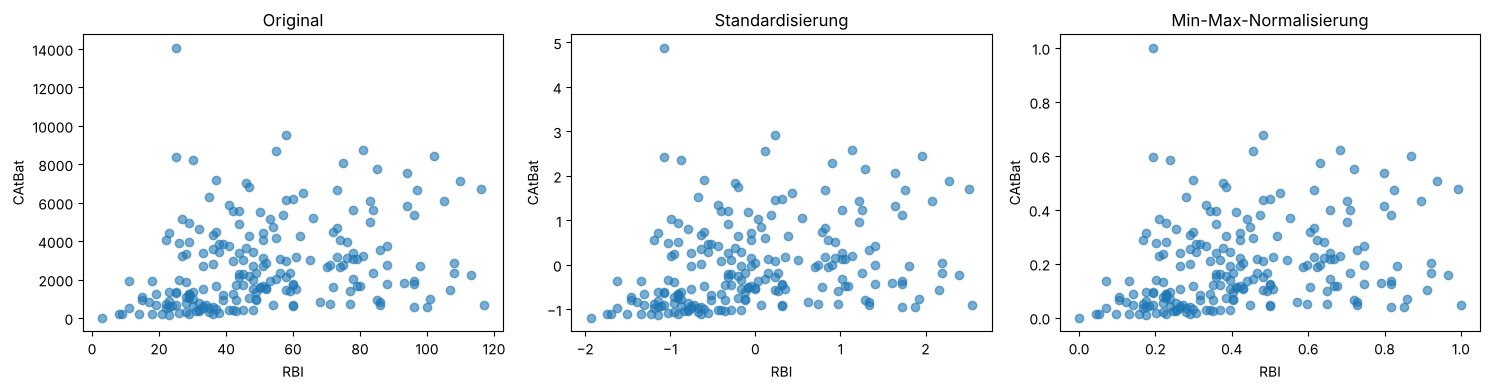

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, values) in zip(axes, [
        ("Original", X_train_fe[demo_cols].values),
        ("Standardisierung", std.transform(X_train_fe[demo_cols])),
        ("Min-Max-Normalisierung", mm.transform(X_train_fe[demo_cols]))]):
    ax.scatter(values[:, 0], values[:, 1], alpha=0.6)
    ax.set_title(title); ax.set_xlabel("RBI"); ax.set_ylabel("CAtBat")
plt.tight_layout(); plt.show()

Die Form der Punktwolke bleibt gleich, nur die **Achsen** ändern sich.
Wichtig: Testdaten werden mit den Parametern aus dem Training transformiert und können daher auch außerhalb von [0, 1] liegen (hier `RBI`):

In [21]:
print("Min/Max Test nach MinMaxScaler:", mm.transform(X_test_fe[demo_cols]).min(axis=0).round(2),
      mm.transform(X_test_fe[demo_cols]).max(axis=0).round(2))

Min/Max Test nach MinMaxScaler: [0.04 0.01] [1.04 0.53]


## 6. Alles zusammen: Pipeline
Eine `Pipeline` bündelt alle Vorverarbeitungsschritte mit dem Modell.
`fit` wird nur auf den Trainingsdaten aufgerufen, `predict` wendet dieselben Schritte auf die Testdaten an.
Den `SimpleImputer` brauchen wir hier nicht zwingend, er schützt aber vor fehlenden Werten in neuen Daten.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

cat_cols = ["League", "Division"]
num_cols = [c for c in X_train_fe.columns if c not in cat_cols]

preprocessing = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

model = Pipeline([("prep", preprocessing), ("reg", LinearRegression())])
model.fit(X_train_fe, y_train)
pred = model.predict(X_test_fe)
print(f"Test-MAE: {mean_absolute_error(y_test, pred):.0f} Tsd. $   R²: {r2_score(y_test, pred):.2f}")

Test-MAE: 195 Tsd. $   R²: 0.62


### Bringt das Feature Engineering etwas?
Vergleich mit einem Modell, das nur die ursprünglichen numerischen Spalten nutzt:

In [23]:
raw_cols = X_train.select_dtypes("number").columns
baseline = Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())])
baseline.fit(X_train[raw_cols], y_train)
pred_base = baseline.predict(X_test[raw_cols])
print(f"Ohne Feature Engineering: MAE {mean_absolute_error(y_test, pred_base):.0f}   R²: {r2_score(y_test, pred_base):.2f}")
print(f"Mit Feature Engineering:  MAE {mean_absolute_error(y_test, pred):.0f}   R²: {r2_score(y_test, pred):.2f}")

Ohne Feature Engineering: MAE 186   R²: 0.62
Mit Feature Engineering:  MAE 195   R²: 0.62


Kaum ein Unterschied. Feature Engineering ist **kein Selbstläufer**: Jede Idee muss evaluiert werden.
Bei nur 53 Testbeispielen hängt das Ergebnis außerdem stark vom zufälligen Split ab.
Für einen belastbaren Vergleich brauchen wir **Kreuzvalidierung** → nächste Vorlesung.

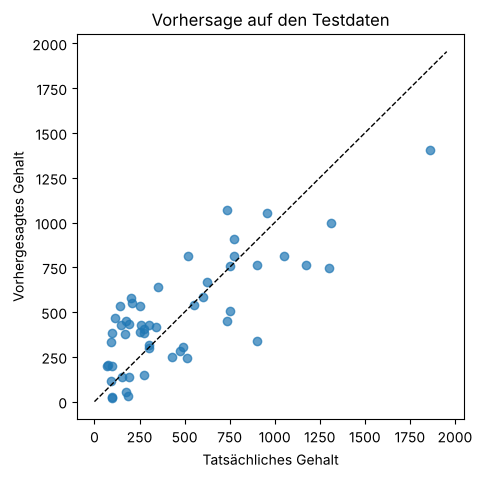

In [24]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.7)
lim = [0, y_test.max() * 1.05]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("Tatsächliches Gehalt"); plt.ylabel("Vorhergesagtes Gehalt")
plt.title("Vorhersage auf den Testdaten")
plt.show()

## Zusammenfassung
| Schritt | Werkzeug |
|---|---|
| Daten laden | `pd.read_csv` |
| EDA | `info`, `describe`, `histplot`, `boxplot`, `corr` + `heatmap` |
| Bereinigung | `str.strip`, `duplicated`, `dropna`, IQR-Regel |
| Split | `train_test_split` (vor allen `fit`-Schritten!) |
| Feature Engineering | eigene Funktion, `get_dummies` / `OneHotEncoder` |
| Scaling | `StandardScaler`, `MinMaxScaler` |
| Gesamt | `ColumnTransformer` + `Pipeline` |